# Tutorial 02

This is the notebook to walk through in class. Run the cells from top to bottom. Later cells use names created above.

A regression model predicts a number. We fit a straight line, then a curve that can bend, then ridge and lasso, which shrink the coefficients.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `FD_data.csv`, `data_X.csv`, and `3d_daily.npy`.
- **On your own computer.** Open this file from the `02 Regression models` folder, so those files sit beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "02 Regression models"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/02 Regression models


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn fits the models.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


## A line, written as a product

Each row is one record. The first column of `X` is all ones, so the line can have an intercept. The other columns are the features. `y` is the target, one number per row.

The fitted weights are

`w = inv(X.T @ X) @ X.T @ y`

`w[0]` is the intercept. The rest are the slopes.


In [4]:
X = np.array([[1, 1, 2, 3],
              [1, 2, 3, 5],
              [1, 4, 3, -1],
              [1, 8, 6, 4]])
y = np.array([4, 8, 5, 10]).reshape(-1, 1)

print(X.shape)
print(y.shape)


(4, 4)
(4, 1)


In [5]:
w = np.linalg.inv(X.T @ X) @ X.T @ y

print("w1~n is", w[1:].flatten())
print("w0 is", w[0])


w1~n is [-9.75 19.25 -2.75]
w0 is [-16.5]


## The same line in scikit-learn

`LinearRegression` adds the intercept itself, so this `X` has no column of ones. The rows are the same four records as above. The slope and the intercept should match `w`.


In [6]:
from sklearn.linear_model import LinearRegression

X = np.array([[1, 2, 3],
              [2, 3, 5],
              [4, 3, -1],
              [8, 6, 4]])
y = np.array([4, 8, 5, 10])

reg = LinearRegression().fit(X, y)

print("w1 is", reg.coef_)
print("w0 is", reg.intercept_)


w1 is [-9.75 19.25 -2.75]
w0 is -16.4999999999999


## Flow against density

`FD_data.csv` has two columns. `k` is density, in veh/km. `q` is flow, in veh/hour.

The cloud rises and then bends down. A straight line can follow the average trend. It cannot follow both the rising part and the falling part.


In [7]:
FD_data = pd.read_csv("FD_data.csv")
FD_data.head()


,k,q
0,21,538
1,6,291
2,8,397
3,5,197
4,9,379


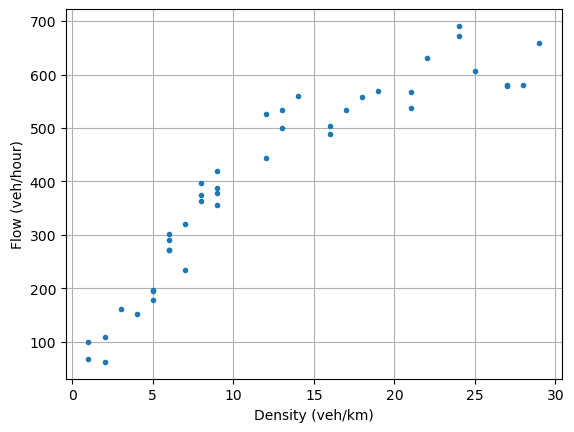

In [8]:
k = FD_data["k"].to_numpy().reshape(-1, 1)
q = FD_data["q"].to_numpy().reshape(-1, 1)

plt.plot(k, q, ".")
plt.xlabel("Density (veh/km)")
plt.ylabel("Flow (veh/hour)")
plt.grid()
plt.show()


## A curve that is still linear in the weights

`PolynomialFeatures(degree=2)` builds two columns from density: `k` and `k` squared. The model is still a linear regression. The weights sit in front of those columns, so the curve can bend.

`include_bias=False` leaves the intercept to `LinearRegression`.


In [9]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
poly_features = poly.fit_transform(k)
print(poly_features.shape)
print(poly_features[:3])


(42, 2)
[[ 21. 441.]
 [  6.  36.]
 [  8.  64.]]


In [10]:
poly_reg_model = LinearRegression()
poly_reg_model.fit(poly_features, q)
y_predicted = poly_reg_model.predict(poly_features)
FD_data["Fitted"] = y_predicted


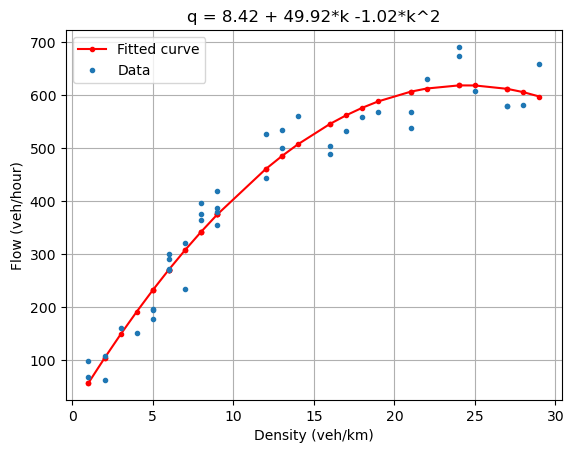

In [11]:
FD_data = FD_data.sort_values(by="k")

plt.plot(FD_data["k"], FD_data["Fitted"], "r.-", label="Fitted curve")
plt.plot(FD_data["k"], FD_data["q"], ".", label="Data")
plt.legend(loc=0)
plt.xlabel("Density (veh/km)")
plt.ylabel("Flow (veh/hour)")
plt.title("q = %.2f + %.2f*k %.2f*k^2" % (
    poly_reg_model.intercept_[0],
    poly_reg_model.coef_[0, 0],
    poly_reg_model.coef_[0, 1],
))
plt.grid()
plt.show()


## Ridge regression

The next table is one row per BART station. We keep the first 48 stations. The last two were not open when this ridership was collected.

The four features are total population, households with no car, total employment, and road density. The target is the total ridership from Embarcadero, the 18th station, to each of those 48 stations. `3d_daily.npy` has shape `(origin, destination, day)`. Summing over days gives the yearly total.

Ridge shrinks the coefficients toward zero. `alpha` sets how strong that shrinkage is. The features and the target are scaled to the range 0 to 1 before the fit, so the coefficients can be compared.


In [12]:
from sklearn import linear_model
from sklearn.preprocessing import minmax_scale

data_BART_sld = pd.read_csv("data_X.csv").iloc[:48, 1:]
data_BART_sld.head()


,TotPop,AutoOwn0,TotEmp,Tot Rd Dens
0,11084,1664,33120,42.232657
1,142973,20505,103479,32.296762
2,36177,4704,47570,31.822631
3,104191,8018,39663,32.894203
4,70630,1142,13924,20.531431


In [13]:
data_BART_sld = data_BART_sld.to_numpy()

# Embarcadero is the 18th station, so its row index is 17.
OD_BART = np.load("3d_daily.npy").sum(axis=2)[17, :48]

print("Shape of data_BART_sld", data_BART_sld.shape)
print("Shape of OD_BART", OD_BART.shape)

X = minmax_scale(data_BART_sld)
y = minmax_scale(OD_BART)
print("Shape of X", X.shape)
print("Shape of y", y.shape)


Shape of data_BART_sld (48, 4)
Shape of OD_BART (48,)
Shape of X (48, 4)
Shape of y (48,)


`get_w(alpha)` fits one ridge model on the scaled `X` and `y`, and returns the intercept and the four coefficients.


In [14]:
def get_w(alpha):
    reg = linear_model.Ridge(alpha=alpha)
    reg.fit(X, y)

    return reg.intercept_, reg.coef_[0], reg.coef_[1], reg.coef_[2], reg.coef_[3]


Fit ridge once for each alpha from 0 to 1. Alpha 0 is an ordinary least-squares line. Larger alpha pulls the coefficients in.


In [15]:
intercept_set = []
coef1_set = []
coef2_set = []
coef3_set = []
coef4_set = []

alpha_set = np.arange(0, 1.05, 0.05)
for alpha in alpha_set:
    intercept, coef1, coef2, coef3, coef4 = get_w(alpha)
    intercept_set.append(intercept)
    coef1_set.append(coef1)
    coef2_set.append(coef2)
    coef3_set.append(coef3)
    coef4_set.append(coef4)


Each line is one coefficient. Watch them move toward zero as alpha grows. Ridge makes them smaller. On this range it does not set them to exactly zero.


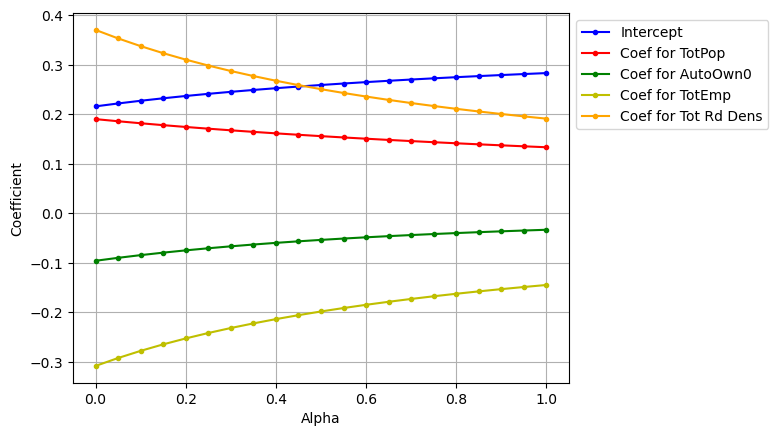

In [16]:
plt.plot(alpha_set, intercept_set, "b.-", label="Intercept")
plt.plot(alpha_set, coef1_set, "r.-", label="Coef for TotPop")
plt.plot(alpha_set, coef2_set, "g.-", label="Coef for AutoOwn0")
plt.plot(alpha_set, coef3_set, "y.-", label="Coef for TotEmp")
plt.plot(alpha_set, coef4_set, ".-", color="orange", label="Coef for Tot Rd Dens")
plt.grid()
plt.legend(bbox_to_anchor=(1, 1))
plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.show()


## Lasso regression

Lasso uses the same scaled table and the same four features. The penalty is different: a coefficient is allowed to land on exactly zero, which drops that feature out of the model.

Lasso reacts at a much smaller alpha than ridge, so the range here stops at 0.05 rather than 1, and it starts just above zero. At alpha exactly 0, scikit-learn tells you to use ordinary least squares instead of lasso. The function below replaces `get_w`. It uses the same scaled `X` and `y`.


In [17]:
def get_w(alpha):
    reg = linear_model.Lasso(alpha=alpha, max_iter=20000)
    reg.fit(X, y)

    return reg.intercept_, reg.coef_[0], reg.coef_[1], reg.coef_[2], reg.coef_[3]


In [18]:
intercept_set = []
coef1_set = []
coef2_set = []
coef3_set = []
coef4_set = []

alpha_set = np.arange(0.001, 0.05, 0.001)
for alpha in alpha_set:
    intercept, coef1, coef2, coef3, coef4 = get_w(alpha)
    intercept_set.append(intercept)
    coef1_set.append(coef1)
    coef2_set.append(coef2)
    coef3_set.append(coef3)
    coef4_set.append(coef4)


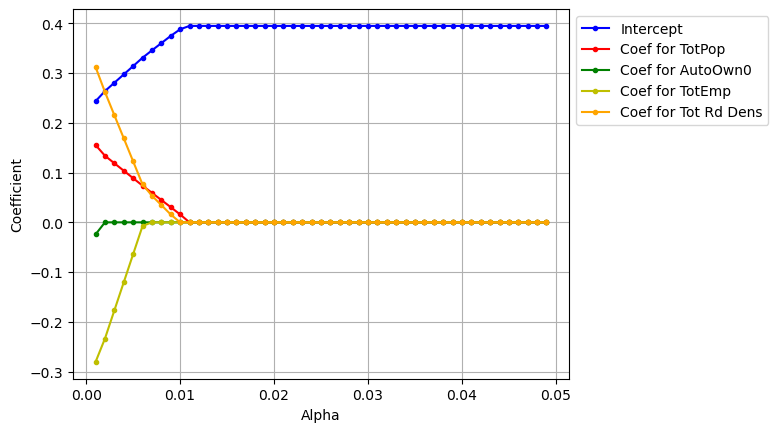

In [19]:
plt.plot(alpha_set, intercept_set, "b.-", label="Intercept")
plt.plot(alpha_set, coef1_set, "r.-", label="Coef for TotPop")
plt.plot(alpha_set, coef2_set, "g.-", label="Coef for AutoOwn0")
plt.plot(alpha_set, coef3_set, "y.-", label="Coef for TotEmp")
plt.plot(alpha_set, coef4_set, ".-", color="orange", label="Coef for Tot Rd Dens")
plt.grid()
plt.legend(bbox_to_anchor=(1, 1))
plt.xlabel("Alpha")
plt.ylabel("Coefficient")
plt.show()
